# A gradient-boosting challenger to the GLM

This notebook fits one LightGBM model with a Tweedie objective to the same data as the final GLM, tunes it by cross-validation
grouped by household, and compares it with the GLM on the 2022 test split and on 2023. It also builds the multiplicative surrogate
tariff of the GBM, so that the comparison is between two things that could be charged. The GLM is not changed. It ends with the
decision for the user: the GLM tariff or the GBM tariff as the basis for pricing.

**Summary.** The GBM does not beat the GLM. On the 2022 test split it has a higher deviance than the GLM technical model and the GLM tariff, a Gini equal to the tariff's and
below the technical model's, and the differences are within sampling noise. It gives about the same A/E and a similar Gini on 2023, and a 2023 deviance that is slightly below the GLM tariff's and slightly above the technical model's.
Its surrogate tariff is a little worse again. The recommendation is the GLM tariff.

### Headline numbers from the saved tables

The table is read from the files named in its last column, saved by the cells below.

In [1]:
import pandas as pd

from health_pricing.models import gbm_summary

pd.options.display.max_colwidth = None
gbm_summary.headline_numbers()

,number,value,source
0,Chosen hyperparameters,"learning rate 0.06, 8 leaves, minimum 150 per leaf, 123 trees",gbm_cv_grid.csv
1,Combinations tried,12,gbm_cv_grid.csv
2,"GBM, test deviance","840,754 (9.4 percent below the baseline)",gbm_scores_2022.csv
3,"GBM tariff, test deviance","843,827 (9.1 percent below the baseline)",gbm_scores_2022.csv
4,"GLM technical model, test deviance","831,786 (10.4 percent below the baseline)",gbm_scores_2022.csv
5,"GLM tariff, test deviance","838,173 (9.7 percent below the baseline)",gbm_scores_2022.csv
6,"Test Gini: GBM, GBM tariff, GLM technical model, GLM tariff","0.378, 0.368, 0.386, 0.378",gbm_scores_2022.csv
7,"Deviance gap, GLM tariff less GBM (test)","-2,581 (-18,656 to 11,028)",gbm_deviance_gaps.csv
8,Share of the GBM's Gini advantage kept by its tariff,"not defined, the GBM has no Gini advantage over the GLM tariff",gbm_survival.csv
9,"A/E on 2023: GBM, GBM tariff, GLM technical model, GLM tariff","1.142, 1.145, 1.145, 1.145",gbm_scores_2023.csv


## Model specification

**Objective and offset.** With $S_i$ the capped annual cost of person-year $i$ (capped at 100,000 dollars) and $t_i$ its exposure in
years, the boosted model $F_M(\mathbf{x}_i) = \sum_{m=1}^{M} \eta\, f_m(\mathbf{x}_i)$ is fitted by minimising the Tweedie deviance
with power 1.5, with the log exposure as an offset (the init score)

$$\hat\mu_i = \exp\big( \log t_i + F_M(\mathbf{x}_i) \big), \qquad
\min_F \sum_i d_{1.5}\big(S_i, \hat\mu_i\big), \qquad
d_p(s, \mu) = 2 \left[ \frac{s^{2-p}}{(1-p)(2-p)} - \frac{s\,\mu^{1-p}}{1-p} + \frac{\mu^{2-p}}{2-p} \right].$$

**Inputs and pricing.** $\mathbf{x}_i$ holds adult age (a number, at most 85, set to 18 for children), the child age bands, region,
the seven condition flags and `inscov`. When pricing, `inscov` is set to its reference level (private), as in the GLM. The
prediction carries the provisional large-claim load $\ell = 0.065$ and the balance factor $\rho$ of 2022 train

$$\hat y_i = \rho\,(1 + \ell)\,\hat\mu_i, \qquad \rho = \frac{\sum_{i \in \text{train}} Y_i}{\sum_{i \in \text{train}} (1 + \ell)\,\hat\mu_i}.$$

**Constraint.** The model is monotone increasing in adult age, $\partial F_M / \partial\, \text{age}_{\text{adult}} \geq 0$, and has no
other constraint.

**Tuning.** Five-fold cross-validation on 2022 train, with folds that hold whole households. The 12 combinations are the learning
rates $\eta \in \{0.03, 0.06\}$, the leaf counts $\{4, 8, 16\}$ and the minimum rows per leaf $\{50, 150\}$. For each combination
early stopping (patience 50) on the held-out fold sets the trees, and the combination with the lowest out-of-fold deviance wins,
with $M$ equal to the mean best iteration of its folds. The seed is fixed, the fit is deterministic and single-threaded, and the
other LightGBM settings are its defaults.

**Surrogate tariff of the GBM.** As for the GLM, a Poisson log-link model with offset $\log t_i$ fitted to the balanced
predictions $\hat y_i$ of train, with the rating factors and five-year age bands

$$\log \tilde y_i = \log t_i + \mathbf{z}_i^{\top}\boldsymbol\kappa .$$

## Data and the GLM it is compared with

The GBM is fitted on the 2022 train split and compared on the 2022 test split, which neither the GBM nor the GLM has used for
fitting or tuning. The GLM is the frozen final structure of `03_glm.ipynb`: the technical model (spline age, 9 rating factors) and
its tariff (five-year age bands). The GBM is **not** given the other controls that the GLM fits (self-rated health, mental health,
exercise and smoking). It sees the 9 rating factors and `inscov`, as specified.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from health_pricing.models import agecurve, figures, gbm, monitoring, outofsample

pd.options.display.float_format = "{:,.3f}".format
frozen = outofsample.freeze()
spline = frozen.final_tariff.frames["spline"]
train, test = spline.train, spline.test
inputs = gbm.feature_matrix(train)
inputs.describe().loc[["min", "max"]]

C:\Users\ardih\Portfolio\Health_Pricing_MEPS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,age_group3,age_adult,region,HIBPDX,CHDDX,OHRTDX,CHOLDX,CANCERDX,ARTHDX,ASTHDX,inscov
min,0.000,18.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
max,3.000,85.000,3.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,2.000


## Tuning

Five-fold cross-validation on 2022 train, with every fold holding whole households (`DUID`). The grid is the 12 combinations of two
learning rates, three leaf counts and two minimum leaf sizes. For each combination, early stopping on the number of trees runs on
the held-out fold, and the combination is scored by the Tweedie deviance (power 1.5) of the out-of-fold predictions of capped cost.
The number of trees is the mean best iteration of the five folds. The chosen combination has the lowest deviance.

In [3]:
grid = gbm.tune(train)
gbm.save_table(grid, "gbm_cv_grid.csv")
grid

,learning_rate,num_leaves,min_data_in_leaf,trees,min_trees,max_trees,cv_deviance_p1_5,chosen
0,0.030,4,50,326,224,565,"2,944,899.818",False
1,0.030,4,150,324,233,428,"2,944,958.790",False
2,0.030,8,50,230,197,255,"2,944,136.887",False
3,0.030,8,150,243,201,295,"2,942,037.024",False
4,0.030,16,50,215,198,240,"2,944,965.230",False
5,0.030,16,150,230,194,274,"2,941,136.247",False
6,0.060,4,50,165,111,284,"2,944,312.523",False
7,0.060,4,150,161,108,195,"2,942,785.778",False
8,0.060,8,50,123,101,154,"2,945,089.532",False
9,0.060,8,150,123,96,149,"2,939,961.312",True


In [4]:
fitted = gbm.fit(train, grid)
tariff, train_balanced = gbm.surrogate_tariff(fitted, train, frozen.prepared)
fitted.chosen, fitted.trees, round(fitted.balance, 4)

({'learning_rate': np.float64(0.06), 'num_leaves': 8, 'min_data_in_leaf': 150},
 123,
 0.9381)

## Comparison on the 2022 test split

The scores use the code of the GLM notebook: Tweedie deviance at the powers 1.3, 1.5 and 1.7 (also as a percentage below the
baseline of the train mean), the exposure-weighted Gini and A/E. Costs are scored uncapped. The deviance gap is the deviance of the
first model less that of the second, so a positive gap means the second fits better, with a 95 percent interval from resampling
households with a fixed seed.

In [5]:
scores_train = gbm.scores(frozen, gbm.predictions(frozen, fitted, tariff, "train"), "train")
predicted_test = gbm.predictions(frozen, fitted, tariff, "test")
scores_test = gbm.scores(frozen, predicted_test, "test")
scores_2022 = pd.concat([scores_train, scores_test], ignore_index=True)
gbm.save_table(scores_2022, "gbm_scores_2022.csv")
scores_test[
    [
        "candidate",
        "tweedie_deviance",
        "reduction_pct_dev",
        "reduction_pct_dev_p1_3",
        "reduction_pct_dev_p1_7",
        "gini",
        "a_e",
    ]
]

,candidate,tweedie_deviance,reduction_pct_dev,reduction_pct_dev_p1_3,reduction_pct_dev_p1_7,gini,a_e
0,Baseline (2022 train mean),"928,363.961",0.000,0.000,0.000,0.000,1.089
1,GBM,"840,753.783",9.437,9.897,7.410,0.378,1.077
2,GBM tariff,"843,827.433",9.106,9.557,7.160,0.368,1.080
3,GLM technical model,"831,786.305",10.403,10.857,8.256,0.386,1.081
4,GLM tariff,"838,173.103",9.715,10.166,7.677,0.378,1.081


In [6]:
names = gbm.NAMES
gaps = gbm.deviance_gaps(
    frozen.prepared.test,
    predicted_test,
    [
        (names["glm_tariff"], names["gbm"]),
        (names["glm_technical"], names["gbm"]),
        (names["glm_tariff"], names["gbm_tariff"]),
        (names["gbm"], names["gbm_tariff"]),
    ],
)
gbm.save_table(gaps, "gbm_deviance_gaps.csv")
gaps

,first,second,deviance_gap,lower_95,upper_95,interval_excludes_0
0,GLM tariff,GBM,"-2,580.680","-18,656.040","11,028.016",False
1,GLM technical model,GBM,"-8,967.478","-26,335.020","4,189.420",False
2,GLM tariff,GBM tariff,"-5,654.330","-15,221.912",666.573,False
3,GBM,GBM tariff,"-3,073.650","-20,422.674","15,178.561",False


### Double lift of the GBM against the GLM tariff

Person-years are grouped by the ratio of the GBM's prediction to the tariff's. The model whose A/E is nearer 1 across the groups
tracks cost better.

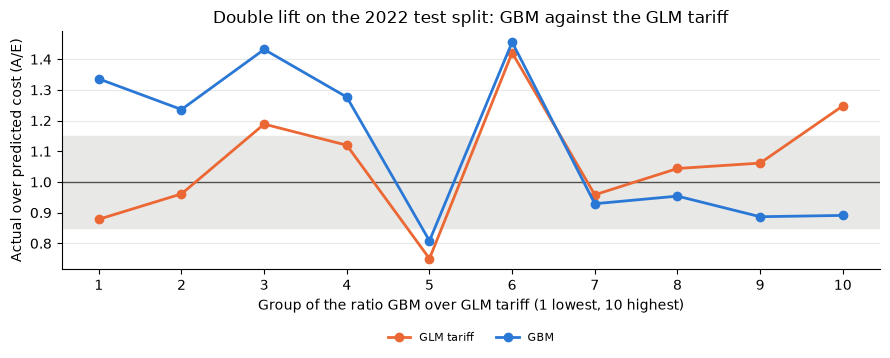

,group,exposure,actual,predicted GBM,predicted GLM tariff,A/E GBM,A/E GLM tariff
0,1,409.917,"566,956.274","424,410.922","645,321.277",1.336,0.879
1,2,410.333,"827,333.225","669,329.757","860,782.874",1.236,0.961
2,3,409.417,"1,074,141.053","750,236.784","903,756.768",1.432,1.189
3,4,410.167,"914,602.840","716,492.160","816,814.466",1.277,1.120
4,5,410.500,"609,804.833","754,426.449","812,885.495",0.808,0.750
5,6,410.083,"1,432,334.981","984,033.283","1,008,040.298",1.456,1.421
6,7,409.417,"761,973.488","820,076.430","795,153.850",0.929,0.958
7,8,410.833,"937,148.645","982,415.334","897,720.619",0.954,1.044
8,9,409.917,"1,238,254.040","1,396,327.709","1,166,530.743",0.887,1.061
9,10,409.750,"1,386,433.870","1,555,891.718","1,111,054.562",0.891,1.248


In [7]:
double = gbm.double_lift(frozen.prepared.test, predicted_test, names["gbm"], names["glm_tariff"])
gbm.save_table(double, "gbm_double_lift.csv")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axhline(1.0, color="#52514e", linewidth=1)
ax.axhspan(0.85, 1.15, color="#e8e8e6", zorder=0)
for name, colour in ((names["glm_tariff"], "#eb6834"), (names["gbm"], "#2a78d6")):
    ax.plot(
        double["group"], double[f"A/E {name}"], color=colour, marker="o", linewidth=2, label=name
    )
ax.set_xticks(range(1, 11))
ax.set_xlabel("Group of the ratio GBM over GLM tariff (1 lowest, 10 highest)")
ax.set_ylabel("Actual over predicted cost (A/E)")
ax.set_title("Double lift on the 2022 test split: GBM against the GLM tariff")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.grid(axis="y", color="#e8e8e6", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
figures.save_figure(fig, "double_lift_gbm_glm", gbm.OUTPUT_DIR / "figures")
plt.show()
double

## Surrogate tariff of the GBM

A multiplicative log-link GLM is fitted to the GBM's balanced train predictions with the same rating factors and five-year age
bands as the GLM tariff, so it can be written as a rating table. It is scored in the same way. The share of the GBM's advantage
over the GLM tariff that the surrogate keeps is its advantage over the GLM tariff divided by the GBM's, for the Gini and for the
deviance. A negative advantage means the GBM does not beat the GLM tariff.

In [8]:
survival = pd.DataFrame(
    [
        {"measure": "gini", **gbm.survival(scores_test, "gini")},
        {"measure": "tweedie_deviance", **gbm.survival(scores_test, "tweedie_deviance")},
    ]
)
gbm.save_table(survival, "gbm_survival.csv")
survival

,measure,gbm_advantage,surrogate_advantage,share_kept
0,gini,-0.000,-0.011,NaN
1,tweedie_deviance,"-2,580.680","-5,654.330",NaN


## SHAP: what the GBM learned

SHAP values are on the log scale of expected cost. The summary plot ranks the inputs and shows the direction of their effect. The
second chart puts the GBM's age effect (the mean SHAP value of adult age by year, relative to age 67) next to the GLM's smooth
age curve (the log of the combined relativity against age 67). The GBM's age effect can only rise, by construction.

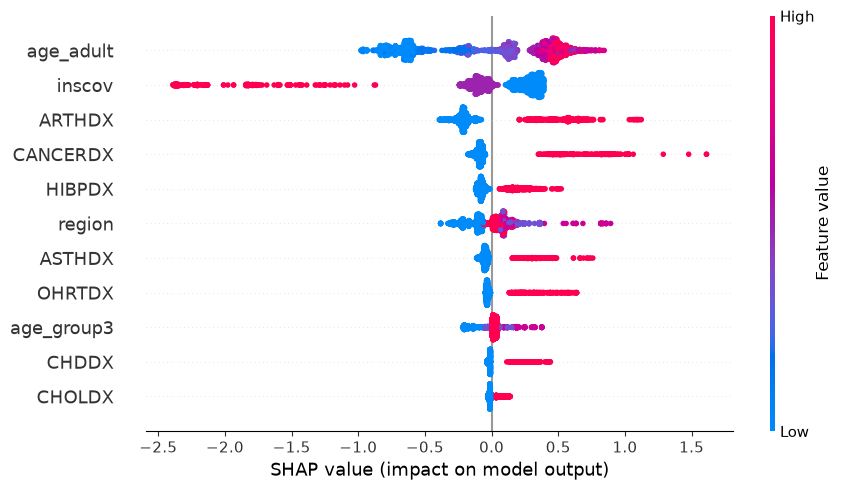

In [9]:
sample = inputs.sample(3000, random_state=gbm.SEED)
sample_values = gbm.shap_values(fitted, sample)
shap.summary_plot(sample_values, sample, show=False, plot_size=(9, 5))
fig = plt.gcf()
plt.tight_layout()
figures.save_figure(fig, "shap_summary", gbm.OUTPUT_DIR / "figures")
plt.show()

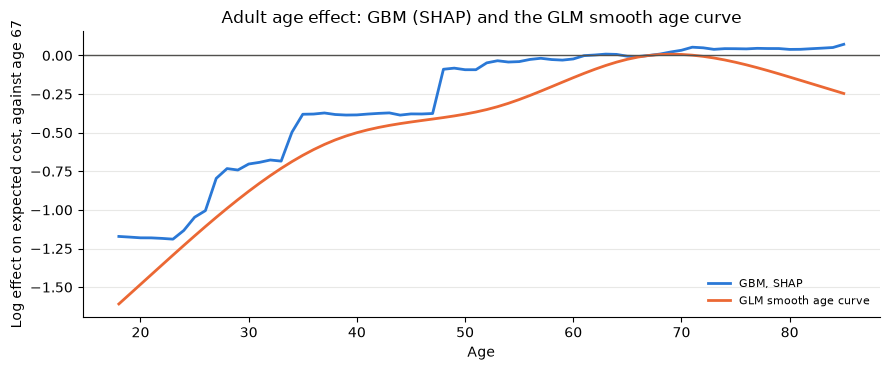

In [10]:
all_values = gbm.shap_values(fitted, inputs)
gbm_age = gbm.shap_age_curve(all_values, inputs)
glm_age = agecurve.spline_curve(frozen.spline)
age_curves = gbm_age.merge(glm_age[["age", "combined_relativity"]], on="age")
age_curves["glm_log_effect"] = np.log(age_curves["combined_relativity"])
gbm.save_table(age_curves, "gbm_shap_age_curve.csv")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(
    age_curves["age"], age_curves["gbm_log_effect"], color="#2a78d6", linewidth=2, label="GBM, SHAP"
)
ax.plot(
    age_curves["age"],
    age_curves["glm_log_effect"],
    color="#eb6834",
    linewidth=2,
    label="GLM smooth age curve",
)
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_xlabel("Age")
ax.set_ylabel("Log effect on expected cost, against age 67")
ax.set_title("Adult age effect: GBM (SHAP) and the GLM smooth age curve")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="y", color="#e8e8e6", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
figures.save_figure(fig, "shap_age_vs_glm", gbm.OUTPUT_DIR / "figures")
plt.show()

In [11]:
interactions = gbm.top_interactions(fitted, inputs.sample(1500, random_state=gbm.SEED))
gbm.save_table(interactions, "gbm_interactions.csv")
interactions

,feature_a,feature_b,mean_abs_interaction
0,age_adult,inscov,0.036
1,CANCERDX,ARTHDX,0.028
2,HIBPDX,inscov,0.027
3,age_adult,region,0.027
4,region,inscov,0.027


## Scored on 2023 with the decided trend

The GBM and its tariff are scored on the 2023 rows with the decided forecast trend of 1.019 on expected cost, next to the GLM. Nothing
is refitted on 2023.

In [12]:
oot = outofsample.load_out_of_time(frozen)
predicted_2023 = gbm.forecast_predictions(frozen, oot, fitted, tariff, 1.019)
overall_2023 = monitoring.overall(oot, predicted_2023)
scores_2023 = monitoring.scores(frozen, oot, predicted_2023)
gbm.save_table(overall_2023, "gbm_ae_2023.csv")
gbm.save_table(scores_2023, "gbm_scores_2023.csv")
scores_2023[["candidate", "tweedie_deviance", "deviance_reduction_pct", "gini", "a_e"]]

,candidate,tweedie_deviance,deviance_reduction_pct,gini,a_e
0,Baseline (2022 train mean),"4,196,352.667",0.000,0.000,1.169
1,GBM,"3,518,699.911",16.149,0.469,1.142
2,GBM tariff,"3,554,354.018",15.299,0.460,1.145
3,GLM technical model,"3,506,652.712",16.436,0.473,1.145
4,GLM tariff,"3,539,069.152",15.663,0.468,1.145


## Diagnostic: the GBM without the age constraint

This is a diagnostic and not a pricing candidate. The GBM is refitted once without the monotone constraint on adult age, with the tuned
values and the same number of trees (no re-tuning), to show what the constraint costs on the data. The constraint stays for
pricing, because UK private medical premiums rise with age. The table gives the test scores next to the constrained GBM and the GLM
tariff, and the mean predicted cost of adult rows at ages 80 to 85 as a ratio to age 67.

In [13]:
free = gbm.fit_unconstrained(train, fitted)
free_name = "GBM, no age constraint (diagnostic)"
compared = {
    names["gbm"]: predicted_test[names["gbm"]],
    free_name: free.predict(test),
    names["glm_tariff"]: predicted_test[names["glm_tariff"]],
}
scores_free = gbm.scores(frozen, compared, "test")
gbm.save_table(scores_free, "gbm_unconstrained_scores.csv")
scores_free[["candidate", "tweedie_deviance", "reduction_pct_dev", "gini", "a_e"]]

,candidate,tweedie_deviance,reduction_pct_dev,gini,a_e
0,Baseline (2022 train mean),"928,363.961",0.000,0.000,1.089
1,GBM,"840,753.783",9.437,0.378,1.077
2,"GBM, no age constraint (diagnostic)","843,560.509",9.135,0.372,1.080
3,GLM tariff,"838,173.103",9.715,0.378,1.081


In [14]:
adults = train[train["age_group3"].astype(str) == "adult"]
old_ages = range(80, 86)
profile = gbm.age_profile(fitted, adults, old_ages).rename(
    columns={"ratio_to_67": "GBM constrained"}
)
profile["GBM no constraint (diagnostic)"] = gbm.age_profile(free, adults, old_ages)["ratio_to_67"]
profile["GLM smooth age curve"] = (
    glm_age.set_index("age").loc[list(old_ages), "combined_relativity"].to_numpy()
)
gbm.save_table(profile, "gbm_age_80_85.csv")
profile

,age,GBM constrained,GBM no constraint (diagnostic),GLM smooth age curve
0,80,1.061,1.004,0.870
1,81,1.061,0.995,0.851
2,82,1.061,0.934,0.833
3,83,1.061,0.914,0.816
4,84,1.061,0.914,0.799
5,85,1.090,0.969,0.782


## Findings

**Accuracy on the 2022 test split.** The GBM has a deviance of 840,754 (9.4 percent below the baseline) and a Gini of 0.378. The GLM
technical model has 831,786 (10.4 percent) and 0.386, and the GLM tariff has 838,173 (9.7 percent) and 0.378. The deviance gap
between the GLM tariff and the GBM is -2,581 (interval -18,656 to 11,028), which means the GLM is slightly better and the gap is
well within noise. The same holds against the GLM technical model (-8,967, interval -26,335 to 4,189). The double lift of the GBM against the GLM tariff has the GLM tariff nearer 1 in 8 of 10 groups and the GBM nearer in 2 (groups 5 and 10, where in group 10 the A/E is 0.89 for the GBM against 1.25 for the tariff). The double lift carries no bands, so the difference is not tested, but it favours the GLM tariff. The grid itself is flat: the cross-validated deviance
of the 12 combinations lies within 0.3 percent, so the choice of hyperparameters changes little.

**The surrogate tariff.** The tariff of the GBM has a deviance of 843,827 and a Gini of 0.368. It is 3,074 worse than the GBM in
deviance and 0.010 lower in Gini, and 5,654 worse than the GLM tariff in deviance (interval -15,222 to 667). Because the GBM has no
advantage over the GLM tariff, there is no advantage for the surrogate to keep.

**On 2023.** With the decided trend of 1.019, the A/E is 1.142 for the GBM and 1.145 for the other three, and the Gini is 0.469 for the
GBM, 0.460 for its tariff, 0.473 for the GLM technical model and 0.468 for the GLM tariff. On deviance the GBM is 3,518,700 (16.1 percent below the baseline), which is 0.6 percent lower than the GLM tariff (3,539,069, 15.7 percent) and 0.3 percent higher than the GLM technical model (3,506,653, 16.4 percent), and its tariff is 3,554,354 (15.3 percent). So the GBM beats the GLM tariff slightly on 2023 deviance, but not the GLM technical model, and its own tariff is worse than the GLM tariff.

**Shapes and interactions.** The SHAP summary ranks adult age and `inscov` first, then the arthritis, cancer and high blood pressure
flags. The conditions all raise expected cost, as in the GLM. For age, the GBM rises more steeply than the GLM between 24 and 35
and is flat from about 50, with steps at some ages that look like noise. It cannot fall after 67 because of the monotone constraint,
whereas the GLM falls to about 0.8 of its level at 67 by age 85, so the GBM is about 30 percent higher at ages 80 to 85. The
largest interactions are small (a mean absolute value of 0.036 on the log scale for adult age with `inscov`, and 0.028 for cancer
with arthritis), and among the rating factors the GBM finds no interaction that the GLM misses.

**The age constraint, as a diagnostic.** Without the monotone constraint, and with the tuned values kept, the GBM has a test deviance of
843,561 and a Gini of 0.372, against 840,754 and 0.378 for the constrained GBM and 838,173 and 0.378 for the GLM tariff, so the
constraint costs nothing on the data. At ages 80 to 85 the mean predicted cost against age 67 is 1.06 to 1.09 for the constrained GBM,
0.91 to 1.00 for the unconstrained one and 0.87 to 0.78 for the GLM curve. The unconstrained GBM falls a little at old ages, less than
the GLM, and it is not a pricing candidate. The constraint stays, because UK private medical premiums rise with age.

## Decision gate: the basis for pricing

The choice is between the **GLM tariff** (26 parameters, relativities with intervals, smooth age) and the **surrogate tariff of the
GBM** as the basis for pricing.

**Decision (the user): the GLM tariff.** The evidence is that the GBM does not beat it on the 2022 holdout (the gaps are within noise), the GLM tariff is nearer 1 in 8 of 10 double-lift groups, and SHAP finds no interaction among the rating factors that the GLM misses. The recommendation was the same. It has the lower deviance and the higher Gini than the GBM tariff on the 2022 test split
(838,173 and 0.378 against 843,827 and 0.368), it also beats the GBM tariff on 2023 (deviance 3,539,069 against 3,554,354 and Gini 0.468 against 0.460), its relativities have intervals, and its age
curve is smooth and allowed to fall at old ages. The GBM tariff adds no accuracy, so it adds complexity without a benefit. The GBM
stays as a challenger, and the test can be repeated with more years or with more inputs in M6.

## Limitations

- The GBM is given only the 9 rating factors and `inscov`, as specified, and not the health and exercise controls that the GLM fits.
  A GBM with those inputs could do better, and the comparison would then favour a model that uses information the tariff cannot.
- The test split is small and heavy-tailed, so the differences between the models are within noise. The result says that the GBM does
  not clearly beat the GLM here, and not that it never could.
- The grid has 12 combinations and is flat, and one seed is used.
- The monotone constraint on age was specified, and it removes the fall at old ages that the GLM curve shows. The diagnostic refit without it is no better on the test split.
- A GBM given the health and exercise controls is an optional test that has not been run.